# 2. Looking at pixels: why a one-line index is a strong baseline

Before any machine learning it pays to understand the physics. If physics alone nearly solves
the problem, a deep model has little room to help, and you want to know that up front.

Here we open one Sentinel-2 scene of Lake Travis and ask: what does water look like in each
band, and how well does a simple band ratio separate it from land?

In [1]:
from hlw.nb import BLUE, GREEN, GREY, ORANGE, setup

setup()
import json

import matplotlib.pyplot as plt
import numpy as np

from hlw import aoi, indices
from hlw import config as C
from hlw.blogfigs import rgb
from hlw.dataset import s2_path, s2_scl_path
from hlw.io import read_raster


LAKE, DATE = "travis", "2023-10-16"  # near the 2023 drought low: lots of exposed shore
refl, transform, crs = read_raster(s2_path(LAKE, DATE))
scl = read_raster(s2_scl_path(LAKE, DATE))[0][0]
zone, _, _ = aoi.load_zone(LAKE)
jrc = aoi.load_jrc(LAKE)
valid = zone & (refl[2] > 0) & ~np.isin(scl, C.SCL_INVALID)
print(refl.shape, refl.dtype, "| bands:", C.S2_BANDS)
print(f"{valid.sum():,} valid pixels in the zone = {valid.sum() * 100 / 1e6:.0f} km²")

(12, 3035, 4041) uint16 | bands: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']
1,836,308 valid pixels in the zone = 184 km²


The file holds 12 Sentinel-2 Level-2A bands as surface reflectance × 10,000 (so 1,000 means
10 % of sunlight reflected). Pixels outside the lake zone were zeroed when we downloaded it,
to keep files small.

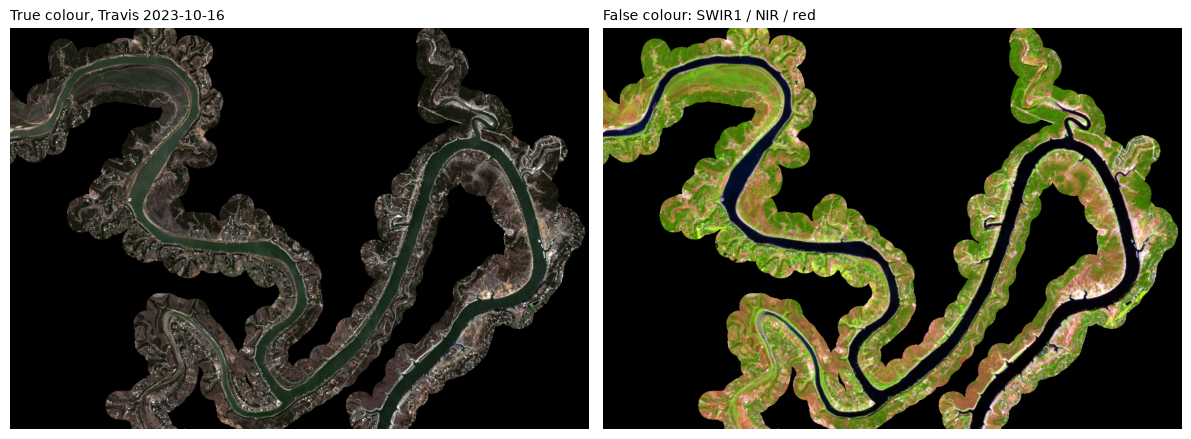

In [2]:
H, W = 900, 1300
y0, x0 = 1000, 1350  # a window over the upper lake with wide drought-exposed banks
sl = (slice(y0, y0 + H), slice(x0, x0 + W))
fc = refl[[10, 7, 3]][:, sl[0], sl[1]].astype(float)  # SWIR1, NIR, red
lo, hi = np.percentile(fc[:, valid[sl]], [1, 99.5], axis=1)
fc = np.clip((fc - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1).transpose(1, 2, 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].imshow(rgb(refl, zone & (refl[2] > 0), sl))
axes[0].set_title(f"True colour, {LAKE.title()} {DATE}")
axes[1].imshow(fc)
axes[1].set_title("False colour: SWIR1 / NIR / red")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()

In true colour the water is a muddy green-brown, not so different from the scrubby shore. In
the false-colour view (short-wave infrared, near infrared and red shown as red, green and
blue) it turns almost black, vegetation goes green and bare rock and mud go pink-tan.

That's the key physical fact: **liquid water absorbs infrared strongly**. A few centimetres of
water swallow most near-infrared (NIR, ~0.84 µm) and short-wave infrared (SWIR, ~1.6 µm)
light, so water stays dark there whatever its colour.

Let's check that with real pixels. We take three groups, using the JRC 36-year water history
as a rough guide: pixels that are almost always water, pixels that have never been water, and
the pale "sometimes" band.

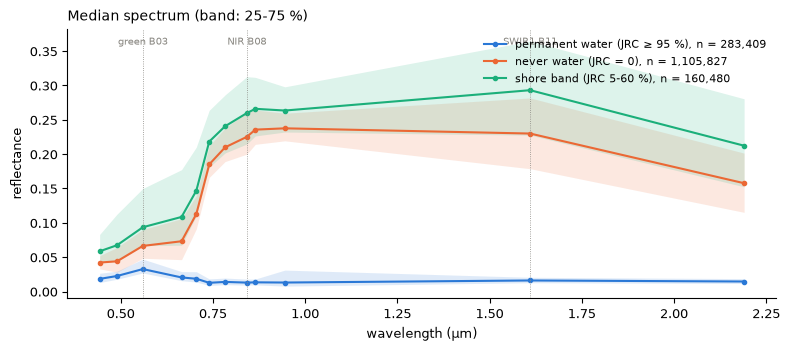

In [3]:
groups = {"permanent water (JRC ≥ 95 %)": (jrc >= 95) & valid,
          "never water (JRC = 0)": (jrc == 0) & valid,
          "shore band (JRC 5-60 %)": (jrc >= 5) & (jrc <= 60) & valid}
wl = [0.443, 0.490, 0.560, 0.665, 0.705, 0.740, 0.783, 0.842, 0.865, 0.945, 1.610, 2.190]
fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, m), c in zip(groups.items(), (BLUE, ORANGE, GREEN)):
    v = refl[:, m].astype(float) / 1e4
    med = np.median(v, 1)
    q1, q3 = np.percentile(v, [25, 75], axis=1)
    ax.plot(wl, med, "-o", ms=3, color=c, label=f"{name}, n = {m.sum():,}")
    ax.fill_between(wl, q1, q3, color=c, alpha=0.15, lw=0)
for b, w in (("green B03", 0.560), ("NIR B08", 0.842), ("SWIR1 B11", 1.610)):
    ax.axvline(w, color=GREY, lw=0.6, ls=":")
    ax.text(w, ax.get_ylim()[1] * 0.97, b, fontsize=7.5, color=GREY, ha="center", va="top")
ax.set(xlabel="wavelength (µm)", ylabel="reflectance", title="Median spectrum (band: 25-75 %)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

Water (blue) is darker than land in *every* band, so "dark = water" alone would also catch
shadows and burnt ground. What is distinctive is the **shape**: water peaks in green and falls
to almost nothing in NIR and SWIR, while land climbs steeply into the infrared (vegetation
reflects NIR strongly; soil and rock are bright in SWIR). The shore band (green line) is a
mixture, as expected: on this date some of it was flooded and most was exposed.

A **normalised difference** turns that contrast into one number per pixel:

* **NDWI** (McFeeters, 1996) = (green − NIR) / (green + NIR)
* **MNDWI** (Xu, 2006) = (green − SWIR1) / (green + SWIR1)

Both run from −1 to +1. For water green beats the infrared band, so the index is positive; for
land it is negative. Dividing by the sum cancels overall brightness (sun angle, slope), so the
index measures the spectrum's shape, not how bright the pixel is.

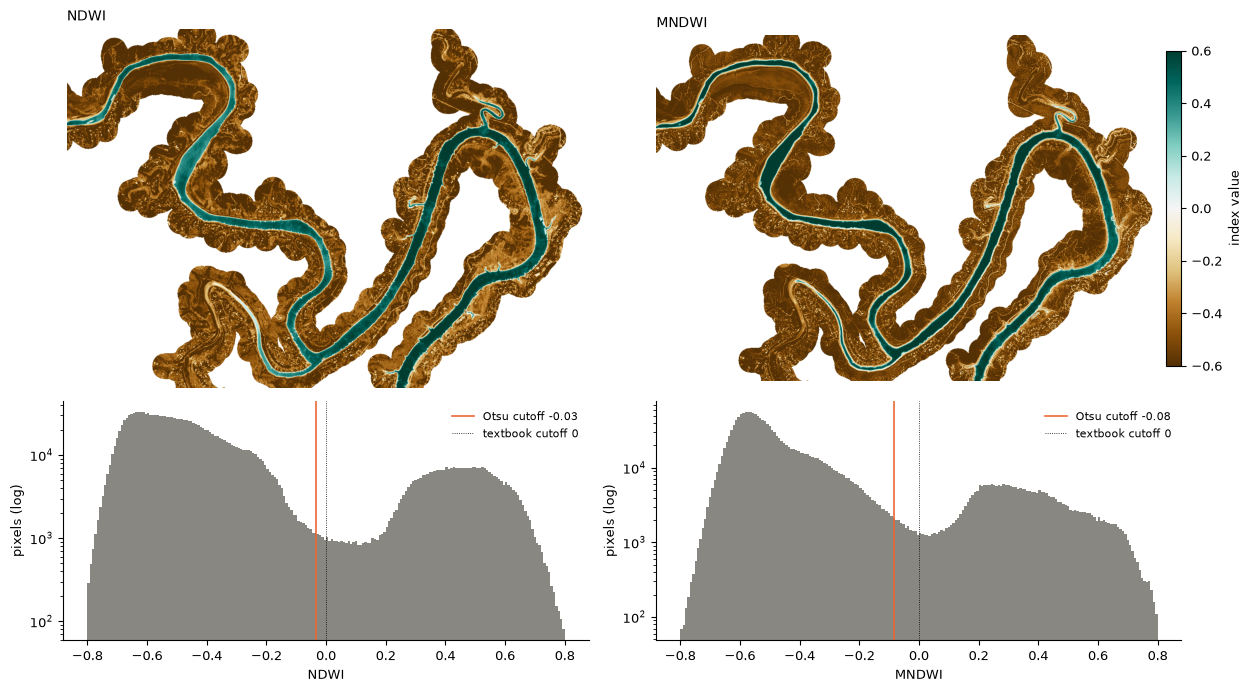

In [4]:
nd, mn = indices.ndwi(refl), indices.mndwi(refl)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), gridspec_kw={"height_ratios": [1.5, 1]})
for j, (name, x) in enumerate((("NDWI", nd), ("MNDWI", mn))):
    im = axes[0, j].imshow(np.where(zone, x, np.nan)[sl], cmap="BrBG", vmin=-0.6, vmax=0.6)
    axes[0, j].set_title(name)
    axes[0, j].set_axis_off()
    v = x[valid]
    t = indices.otsu_cutoff(v)
    axes[1, j].hist(v, bins=200, range=(-0.8, 0.8), color=GREY)
    axes[1, j].axvline(t, color=ORANGE, lw=1.2, label=f"Otsu cutoff {t:.2f}")
    axes[1, j].axvline(0, color="k", lw=0.6, ls=":", label="textbook cutoff 0")
    axes[1, j].set(yscale="log", xlabel=name, ylabel="pixels (log)")
    axes[1, j].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.colorbar(im, ax=axes[0, 1], fraction=0.03, pad=0.02, label="index value")

Both histograms are **bimodal**: a land hump below zero and a water hump above it, with a
valley between. Wherever there is a clean valley, a threshold will work, and
[Otsu's method](https://en.wikipedia.org/wiki/Otsu%27s_method) finds it automatically by
choosing the cut that best separates the two humps.

On this clear autumn scene **both** indices separate the classes well. The maps differ mainly at
the edges: NDWI calls a thin fringe of the shoreline water that MNDWI does not. The
difference between the indices shows up across *dates*, as the next plot shows.

## How much does the cutoff matter, and does it travel?

A threshold method has one free parameter. Let's see how the mapped area of the whole lake
responds to it on two dates: our clear October scene, and 18 June 2023, a hazy summer day with
bright, glinting water.

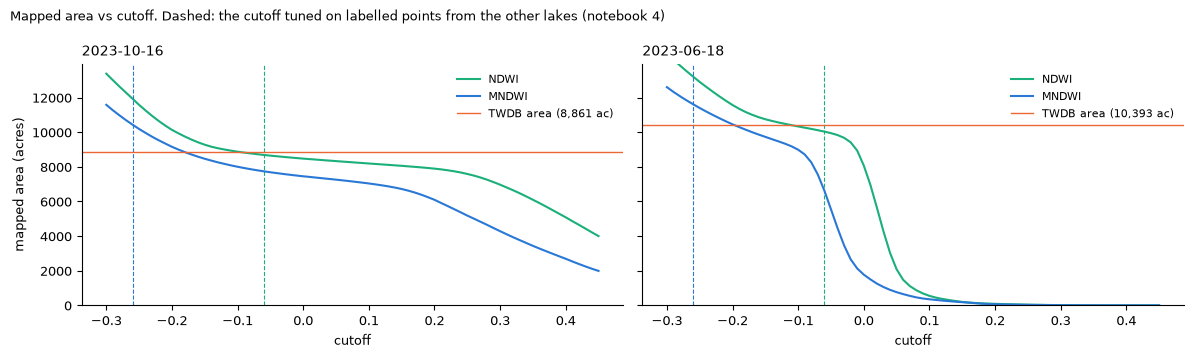

In [5]:
from hlw import levels

tuned = json.loads((C.RESULTS_DIR / "cutoffs.json").read_text())
px_acres = 100 / C.ACRE_M2
cuts = np.linspace(-0.3, 0.45, 76)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, date in zip(axes, (DATE, "2023-06-18")):
    r = read_raster(s2_path(LAKE, date))[0]
    sc = read_raster(s2_scl_path(LAKE, date))[0][0]
    ok = zone & (r[2] > 0) & ~np.isin(sc, C.SCL_INVALID)
    for name, f, c in (("NDWI", indices.ndwi, GREEN), ("MNDWI", indices.mndwi, BLUE)):
        x = f(r)
        ax.plot(cuts, [((x > t) & ok).sum() * px_acres for t in cuts], color=c, label=name)
        ax.axvline(tuned[f"{name.lower()}:{LAKE}"]["cutoff"], color=c, lw=0.8, ls="--")
    twdb = levels.load(LAKE).loc[date, "surface_area"]
    ax.axhline(twdb, color=ORANGE, lw=1, label=f"TWDB area ({twdb:,.0f} ac)")
    ax.set(xlabel="cutoff", title=f"{date}", ylim=(0, None))
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("mapped area (acres)")
fig.suptitle("Mapped area vs cutoff. Dashed: the cutoff tuned on labelled points from the other "
             "lakes (notebook 4)", x=0.01, ha="left", fontsize=9.5)
plt.tight_layout()

A few things to read off this plot:

* Neither curve is perfectly flat. Mapped area always depends somewhat on the cutoff, because
  shoreline pixels are part water and part land and their index values fill the valley.
* **Where the tuned cutoff sits matters more than how flat the curve is.** The NDWI cutoff
  tuned on the other lakes' labels (about −0.06 here) sits in the middle of its gentle
  stretch, close to the textbook value of 0. The MNDWI cutoff (about −0.26) sits further
  out, where MNDWI area is still climbing.
* **The curves move between dates, sometimes a lot.** On the bright June day, glint and haze
  add NIR and SWIR reflectance to the water, and the whole water hump slides towards zero.
  Both curves turn into cliffs. NDWI's cliff starts just above its cutoff, so NDWI still maps
  nearly the whole lake. MNDWI's cliff sits around −0.1, and a cutoff anywhere near the
  textbook 0 would map about a fifth of the lake. This is the single worst date for the
  index baselines in the whole Travis record.

So a cutoff only travels if it sits clear of the cliffs on *every* date, including dates
nobody looked at when tuning it. Notebook 4 tests exactly that, and also shows how much the
answer depends on who labelled the tuning points.

Compare with the orange TWDB line too. At its tuned cutoff NDWI lands within a few percent of
TWDB on both dates, and MNDWI lands above it. Don't read too much into a match with TWDB on
one date, though. TWDB's "area" is the level pushed through a rating curve (notebook 1). The
curve counts flooded vegetation, shallow edges and narrow river arms that a 10 m pixel may see
as land. Notebook 7 compares every method with TWDB over the whole record.

## Takeaways

* Water is physically distinctive in the infrared. A two-band ratio captures most of that.
* Thresholds are only as good as their **transfer**. Evaluate a tuned cutoff on lakes and dates
  it was *not* tuned on; on its tuning data every threshold looks great.
* A deep model can only win where the physics gets muddy: bright or glinting water, haze,
  very turbid inflows, mixed shoreline pixels, flooded vegetation. So the **shoreline** is
  where the contest is. Open water is a foregone conclusion for every method. (Spoiler: on
  single shoreline pixels, plain NDWI turns out to be very hard to beat.)

Next: [3 · labels, weak and hand-made](03_labels.ipynb)